<div align="center">

# Assignment 1 — Linear Regression

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 1 — Linear Regression

**Dataset:** Advertising Budget and Sales (`advertising.csv`)

**Objective:** Predict **Sales** from advertising budgets spent on **TV, Radio and Newspaper**, using simple and multiple linear regression.

## 1. Theory

Linear regression fits a linear equation to the data:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n + \epsilon$$

- $\beta_0$ — intercept
- $\beta_i$ — coefficient (change in $y$ per unit change in $x_i$)
- Model is trained by minimising **Mean Squared Error (MSE)** via Ordinary Least Squares.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')
%matplotlib inline

In [14]:
df = pd.read_csv('advertising.csv', index_col=0)
df.columns = ['TV', 'Radio', 'Newspaper', 'Sales']
df.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [15]:
print('Shape:', df.shape)
df.info()

Shape: (200, 4)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [16]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


## 2. Exploratory Data Analysis

In [17]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

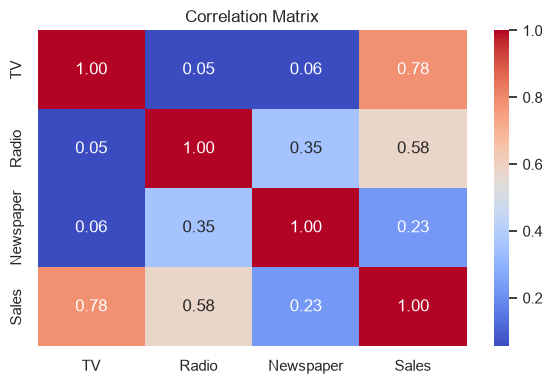

In [18]:
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

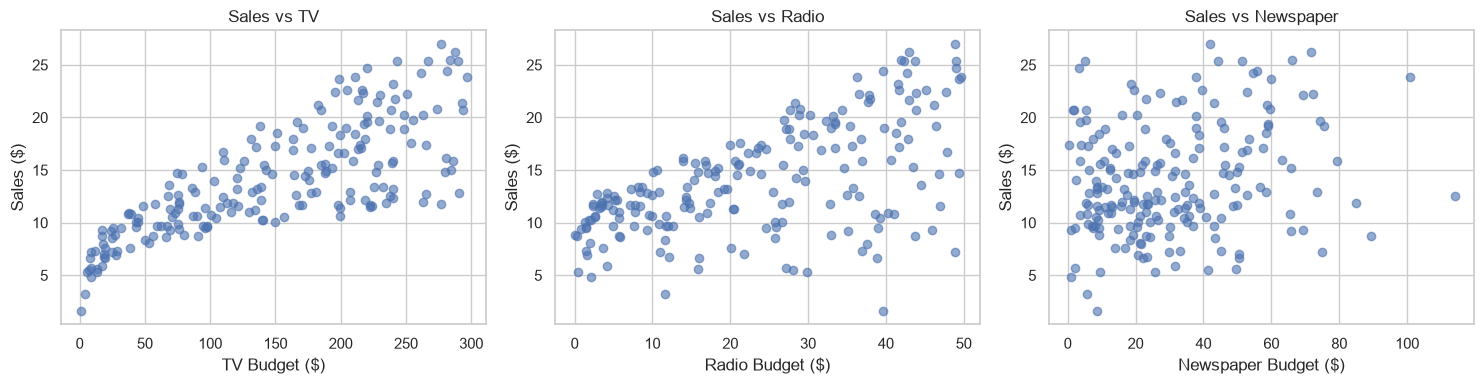

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['TV', 'Radio', 'Newspaper']):
    ax.scatter(df[col], df['Sales'], alpha=0.6)
    ax.set_xlabel(col + ' Budget ($)')
    ax.set_ylabel('Sales ($)')
    ax.set_title(f'Sales vs {col}')
plt.tight_layout()
plt.show()

TV shows the strongest linear relationship with Sales, followed by Radio. Newspaper is weak.

## 3. Simple Linear Regression (one predictor at a time)

In [20]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

for col in ['TV', 'Radio', 'Newspaper']:
    X_simple = df[[col]]
    X_tr, X_te, y_tr, y_te = train_test_split(X_simple, y, test_size=0.2, random_state=42)
    model = LinearRegression().fit(X_tr, y_tr)
    pred = model.predict(X_te)
    print(f'{col:<10} R2 = {r2_score(y_te, pred):.3f}   '
          f'RMSE = {np.sqrt(mean_squared_error(y_te, pred)):.3f}')

TV         R2 = 0.677   RMSE = 3.194
Radio      R2 = 0.263   RMSE = 4.822
Newspaper  R2 = 0.030   RMSE = 5.534


## 4. Multiple Linear Regression (all predictors)

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

print('Intercept :', round(model.intercept_, 4))
for name, c in zip(X.columns, model.coef_):
    print(f'Coefficient of {name:<10}: {c:.4f}')

Train: (160, 3)  Test: (40, 3)
Intercept : 2.9791
Coefficient of TV        : 0.0447
Coefficient of Radio     : 0.1892
Coefficient of Newspaper : 0.0028


In [22]:
y_pred = model.predict(X_test)
comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred.round(2)})
comparison.head(10)

,Actual,Predicted
0,16.9,16.41
1,22.4,20.89
2,21.4,21.55
3,7.3,10.61
4,24.7,22.11
5,12.6,13.11
6,22.3,21.06
7,8.4,7.46
8,11.5,13.61
9,14.9,15.16


## 5. Model Evaluation

In [23]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE  : {mae:.3f}')
print(f'MSE  : {mse:.3f}')
print(f'RMSE : {rmse:.3f}')
print(f'R2   : {r2:.3f}')

MAE  : 1.461
MSE  : 3.174
RMSE : 1.782
R2   : 0.899


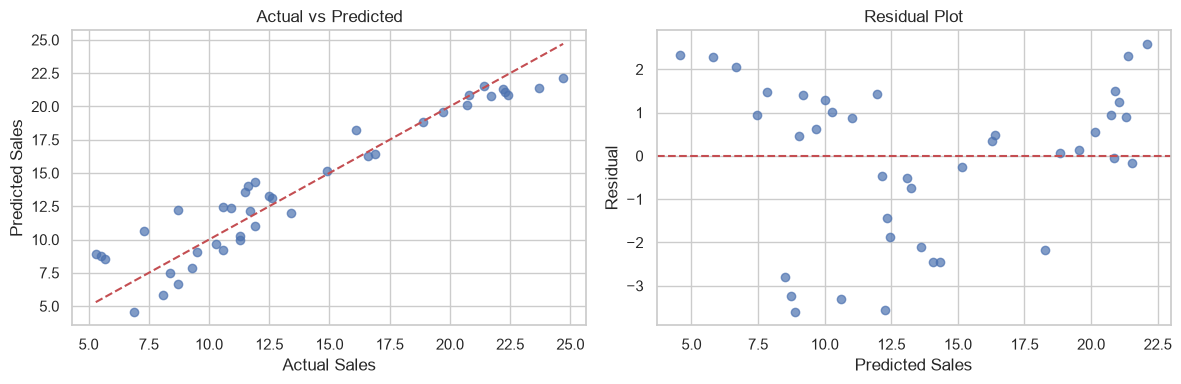

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_test, y_pred, alpha=0.7)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_xlabel('Actual Sales')
axes[0].set_ylabel('Predicted Sales')
axes[0].set_title('Actual vs Predicted')

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.7)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel('Predicted Sales')
axes[1].set_ylabel('Residual')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.show()

Residuals are scattered randomly around zero — no visible pattern, so a linear model is appropriate.

## 6. Conclusion

- Multiple linear regression achieves **R2 ≈ 0.86–0.90** on the test set — far better than any single-predictor model (TV alone ≈ 0.68).
- Every extra **$1,000 on TV** raises sales by ≈ $0.05 units, **Radio** has the largest coefficient (≈ 0.11) and is the most cost-effective channel.
- **Newspaper** contributes almost nothing and is a candidate for budget cuts.